## Padding and Strides in CNNs

### Imports and sample image

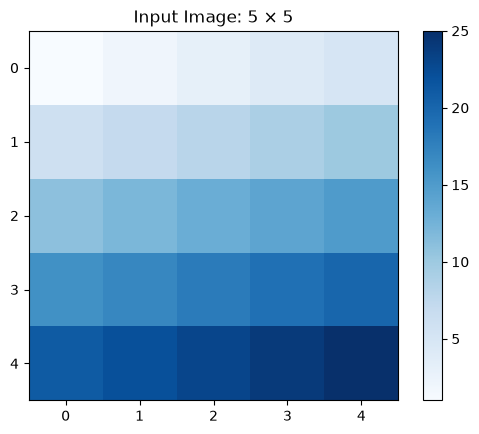

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

image = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
], dtype=np.float32)

kernel = np.ones((3, 3), dtype=np.float32)

plt.imshow(image, cmap="Blues")
plt.title("Input Image: 5 × 5")
plt.colorbar()
plt.show()

### Valid vs Same

VALID output shape: (3, 3)
SAME output shape: (5, 5)


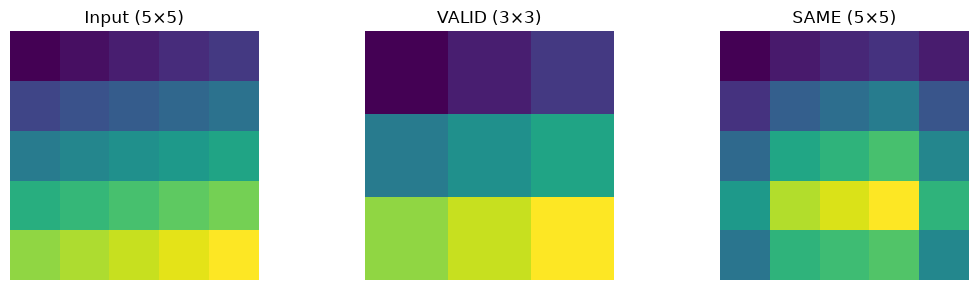

In [2]:
image_tf = tf.constant(image[None, :, :, None])
kernel_tf = tf.constant(kernel[:, :, None, None])

valid = tf.nn.conv2d(
    image_tf, kernel_tf,
    strides=1, padding="VALID"
)

same = tf.nn.conv2d(
    image_tf, kernel_tf,
    strides=1, padding="SAME"
)

valid = valid.numpy()[0, :, :, 0]
same = same.numpy()[0, :, :, 0]

print("VALID output shape:", valid.shape)
print("SAME output shape:", same.shape)

fig, axes = plt.subplots(1, 3, figsize=(11, 3))

for ax, data, title in zip(
    axes,
    [image, valid, same],
    ["Input (5×5)", "VALID (3×3)", "SAME (5×5)"]
):
    ax.imshow(data, cmap="viridis")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Calculate output dimensions

In [3]:
def output_size(N, K, S=1, P=0):
    return (N + 2*P - K) // S + 1

print("VALID:", output_size(N=5, K=3, S=1, P=0))
print("With padding 1:", output_size(N=5, K=3, S=1, P=1))
print("VALID, stride 2:", output_size(N=5, K=3, S=2, P=0))

VALID: 3
With padding 1: 5
VALID, stride 2: 2


### Different strides

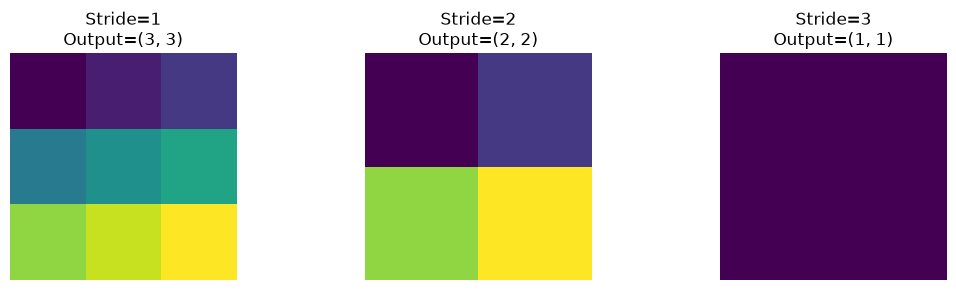

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))

for ax, stride in zip(axes, [1, 2, 3]):
    result = tf.nn.conv2d(
        image_tf,
        kernel_tf,
        strides=[1, stride, stride, 1],
        padding="VALID"
    ).numpy()[0, :, :, 0]

    ax.imshow(result, cmap="viridis")
    ax.set_title(f"Stride={stride}\nOutput={result.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Zero padding

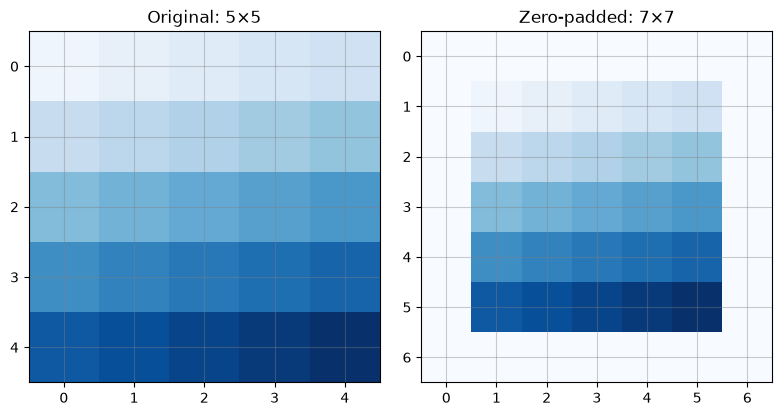

In [5]:
padded = np.pad(image, pad_width=1, mode="constant", constant_values=0)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image, cmap="Blues", vmin=0, vmax=25)
axes[0].set_title("Original: 5×5")

axes[1].imshow(padded, cmap="Blues", vmin=0, vmax=25)
axes[1].set_title("Zero-padded: 7×7")

for ax in axes:
    ax.set_xticks(range(len(image) if ax == axes[0] else len(padded)))
    ax.set_yticks(range(len(image) if ax == axes[0] else len(padded)))
    ax.grid(color="gray", alpha=0.4)

plt.tight_layout()
plt.show()

### Compare

In [6]:
results = []

for padding in ["VALID", "SAME"]:
    for stride in [1, 2, 3]:
        out = tf.nn.conv2d(
            image_tf,
            kernel_tf,
            strides=[1, stride, stride, 1],
            padding=padding
        )

        results.append({
            "Padding": padding,
            "Stride": stride,
            "Output Shape": tuple(out.shape[1:3])
        })

import pandas as pd
pd.DataFrame(results)

,Padding,Stride,Output Shape
0,VALID,1,"(3, 3)"
1,VALID,2,"(2, 2)"
2,VALID,3,"(1, 1)"
3,SAME,1,"(5, 5)"
4,SAME,2,"(3, 3)"
5,SAME,3,"(2, 2)"
